# Chess Data Analysis Pipeline

Tento notebook replikuje logiku ze souboru `main.py` a `data_analysis.py` a rozděluje ji do samostatných bloků pro snadnější spouštění a testování jednotlivých částí procesu analýzy šachových her.

## Příprava dat

### Konfigurace a příprava adresářů

In [1]:
import os
import pandas as pd
from dotenv import load_dotenv
import game_load
import stockfish_eval
import data_analysis

load_dotenv()

True

In [2]:
CHESS_USER = os.getenv("CHESS_USER")
stockfish_path = "stockfish/stockfish-windows-x86-64-avx2.exe"

if CHESS_USER:
    path = CHESS_USER + "_data"
    if not os.path.isdir(path):
        os.mkdir(path)
        print(f"Vytvořena datová složka uživatele: {path}")
    print(f"Pracuji s uživatelem: {CHESS_USER}")
else:
    print("CHESS_USER není nastaven v .env souboru.")

Pracuji s uživatelem: viki953


### 1. Načtení her (Download Games)

In [3]:
def load_games(base_path):
    games_dir = os.path.join(base_path, "games")
    if not os.path.isdir(games_dir):
        os.mkdir(games_dir)

    games_count = game_load.fetch_chess_games(CHESS_USER, games_dir)
    print(f"Staženo {games_count} her uživatele {CHESS_USER}")
    return games_dir

games_path = os.getenv("GAMES_PATH")

if not games_path or not os.path.isdir(games_path):
    print("Games path not found in env or dir missing. Loading games...")
    games_path = load_games(path)
else:
    print(f"Hry již nalezeny v: {games_path}")

Hry již nalezeny v: viki953_data\games


### 2. Analýza her (Stockfish Evaluation)

In [4]:
def analyze_games(games_source, base_path, engine_path):
    analyzed_dir = os.path.join(base_path, "games_analyzed")
    if not os.path.isdir(analyzed_dir):
        os.mkdir(analyzed_dir)

    print("Spouštím Stockfish analýzu...")
    count = stockfish_eval.analyze_archives(games_source, analyzed_dir, engine_path)
    print(f"Her analyzováno: {count}.")
    return analyzed_dir

analyzed_path = os.getenv("ANALYZED_PATH")

# Pokud není cesta v ENV, nebo složka neexistuje, je možné, že chceme spustit analýzu.
# Zde je to zakomentované, aby se nespustilo omylem (trvá dlouho).
# Odkomentujte pro spuštění:

# if not analyzed_path or not os.path.isdir(analyzed_path):
#     analyzed_path = analyze_games(games_path, path, stockfish_path)
# else:
#     print(f"Analyzovaná data nalezená v: {analyzed_path}")

# Pro účely notebooku, pokud cesta není definovaná, zkusíme default:
if not analyzed_path:
    analyzed_path = os.path.join(path, "games_analyzed")
    print("using default fallback path")

print(f"Cesta k analyzovaným datům: {analyzed_path}")

Cesta k analyzovaným datům: viki953_data\games_analyzed


### 3. Analýza Dat (Data Analysis & Statistics)

In [5]:
df_games, df_moves = pd.DataFrame(), pd.DataFrame()
if not os.path.isdir(analyzed_path):
    print(f"Adresář {analyzed_path} neexistuje. Nejdříve spusťte analýzu her.")
elif len(os.listdir(analyzed_path)) == 0:
    print(f"Adresář {analyzed_path} je prázdný. Nejdříve spusťte analýzu her.")
else:
    df_games, df_moves = data_analysis.load_all_data(analyzed_path)

Loading data from 52 files...
Loaded 10106 games and 603785 moves.


## Vizualizace a Statistiky

### Obecné statistiky výher

In [6]:
if not df_games.empty:
    data_analysis.test_game_result_hypothesis(df_games)
    data_analysis.predict_game_result_logistic(df_games)
    data_analysis.test_color_advantage(df_games)


[Statistical Model] Logistic Regression Summary
                           Logit Regression Results                           
Dep. Variable:                 is_win   No. Observations:                10106
Model:                          Logit   Df Residuals:                    10103
Method:                           MLE   Df Model:                            2
Date:                Wed, 07 Jan 2026   Pseudo R-squ.:                  0.1214
Time:                        01:31:16   Log-Likelihood:                -6151.9
converged:                       True   LL-Null:                       -7001.9
Covariance Type:            nonrobust   LLR p-value:                     0.000
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -0.1421      0.031     -4.626      0.000      -0.202      -0.082
rating_diff      0.0156      0.000     36.052      0.000       0.015       0

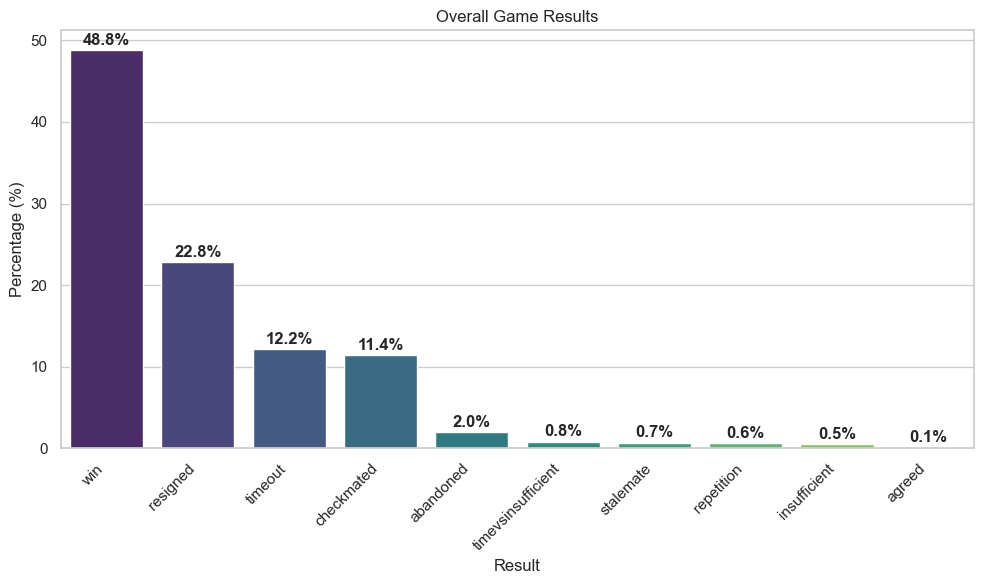

In [7]:
if not df_games.empty:
    data_analysis.plot_winrate_overall(df_games)

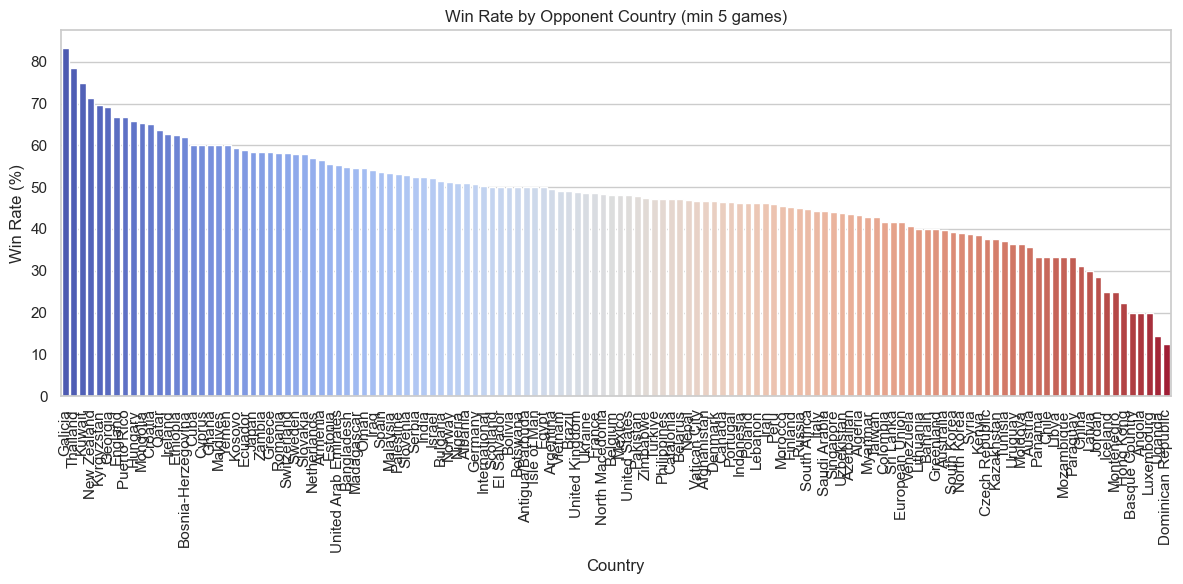

In [8]:
if not df_games.empty:
    data_analysis.plot_country_winrate(df_games)

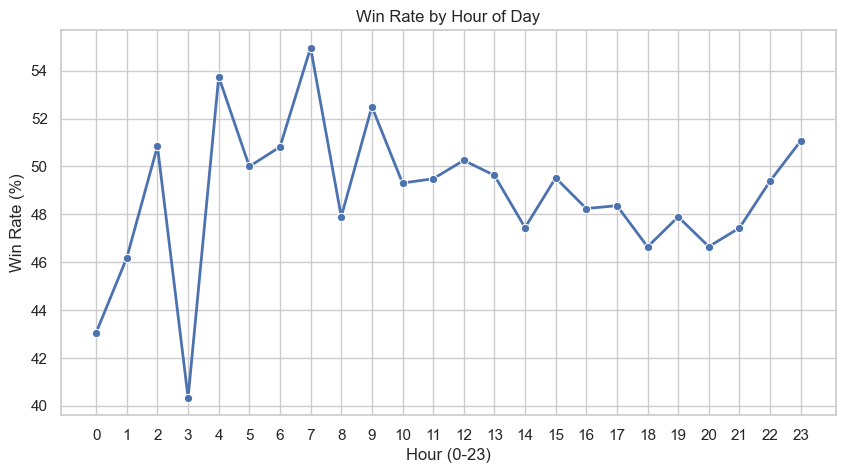

In [9]:
if not df_games.empty:
    data_analysis.plot_hourly_winrate(df_games)

### Analýza matů

In [10]:
if not df_moves.empty:
    data_analysis.test_mate_complexity(df_moves)


[Statistical hypothesis test] Mate Complexity vs Success Rate
Contingency Table (Found vs Not Found by Mate Distance):
found       False  True 
mate_cat                
Mate in 1    1703   1260
Mate in 2    1963    750
Mate in 3    1155    473
Mate in 4+   2956   1309
Chi-Square statistic=178.8608, p-value=1.5541e-38
>> REJECT H0: Success rate significantly depends on mate distance.



--- Missed Mate Analysis ---
            total  found_optimal  found_pattern  optimal_rate  pattern_rate
mate_type                                                                  
Mate in 1    2963           1260           2410     42.524468     81.336483
Mate in 2    2713            750           2203     27.644674     81.201622
Mate in 3    1628            473           1225     29.054054     75.245700
Mate in 4+   4265           1309           2697     30.691676     63.235639


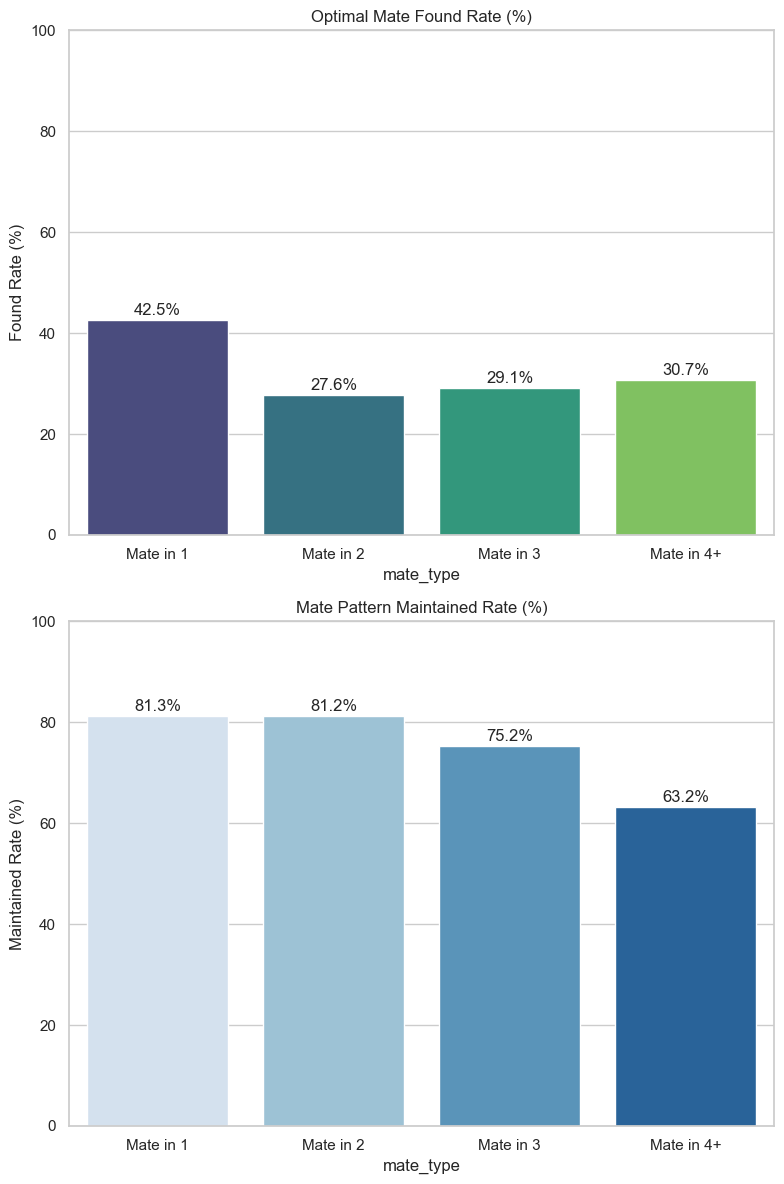

In [11]:
if not df_moves.empty:
    data_analysis.analyze_missed_mates(df_moves)

### Výkonnost dle herních fází

In [12]:
if not df_moves.empty and not df_games.empty:
    data_analysis.predict_win_by_phase(df_moves, df_games)


[Predictive Model] Win Prediction by Phase Performance
Accuracy: 0.60
Feature Importance (coefs): {'Opening': 0.0017134866116987897, 'Middlegame': 0.001186441900106225, 'Endgame': 0.0004515579862749378}
Most influential phase: Opening



[Statistical hypothesis test] Accuracy by Game Phase (ANOVA)
Means: Opening=-57.99, Middlegame=-231.75, Endgame=-187.74
ANOVA result: statistic=488.0634, p-value=2.3913e-212
>> REJECT H0: Significant difference in accuracy between phases.


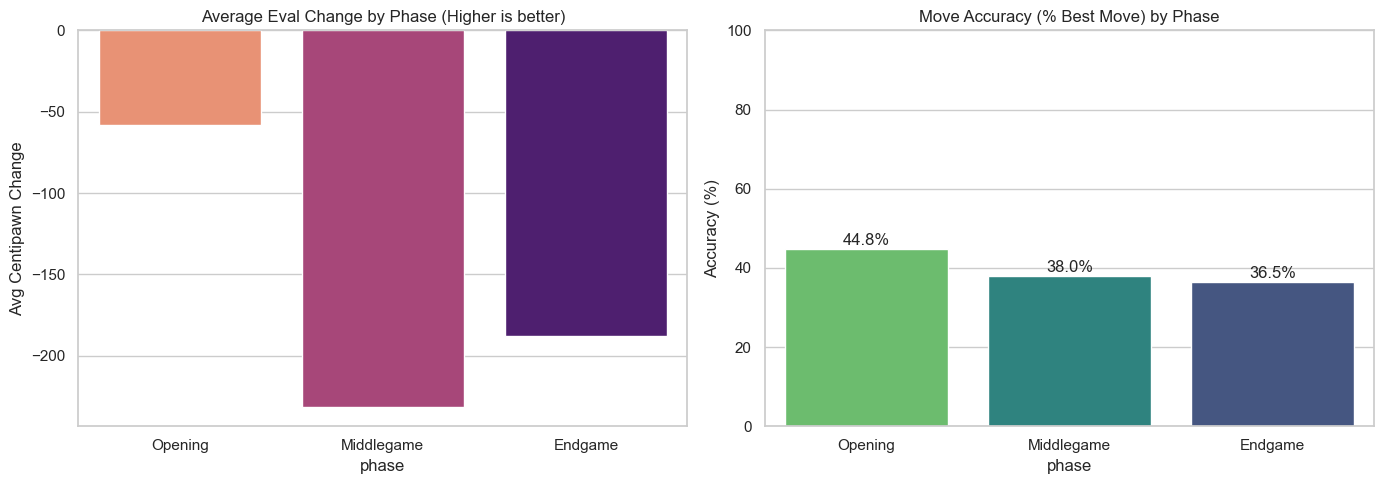

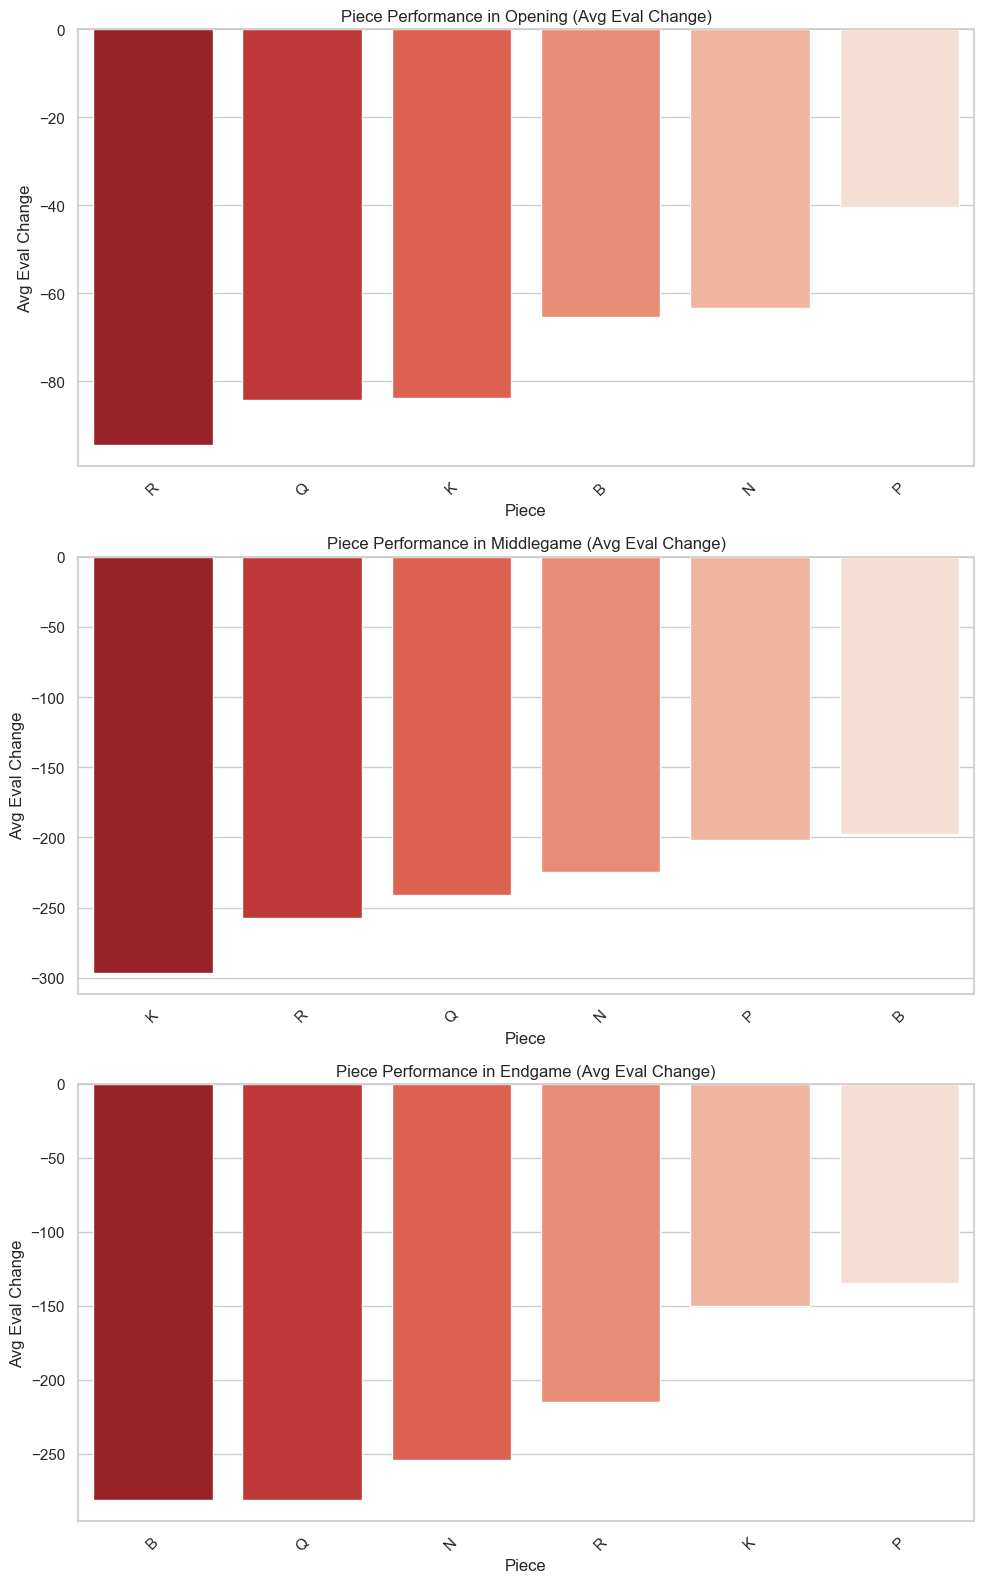

In [13]:
if not df_moves.empty:
    data_analysis.test_phase_accuracy(df_moves)
    data_analysis.analyze_game_phases(df_moves)

### Time Management

In [14]:
if not df_moves.empty:
    data_analysis.predict_blunder_from_time(df_moves)


[Predictive Model] Blunder Prediction from Time
Accuracy (Balanced): 0.62
Time Coef: -0.0081
Negative coef: Less time -> Higher log-odds of blunder (Correct Hypothesis).



[Statistical hypothesis test] Time Pressure vs Move Quality
Using Clock Time: Low < 30s, High > 120s
Samples: Pressure (n=33687), Calm (n=169068)
Means: Pressure=-285.83, Calm=-99.63
T-test result: statistic=-15.9983, p-value=2.0763e-57
>> REJECT H0: Significant difference in move quality found.
Correlation between Time Used and Move Quality (Eval Change): -0.0339


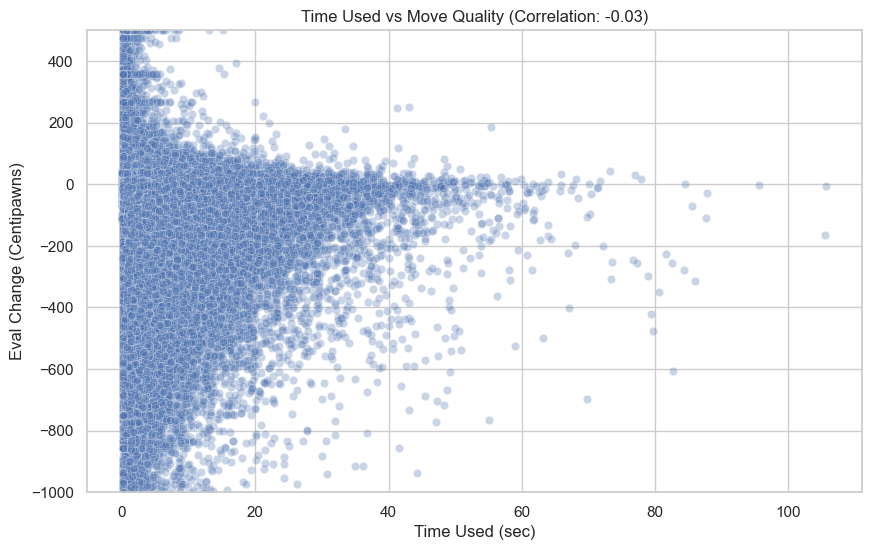

In [15]:
if not df_moves.empty:
    data_analysis.test_time_pressure_vs_quality(df_moves)
    data_analysis.plot_time_vs_quality(df_moves)

### Analýza rošád

In [16]:
if not df_games.empty:
    data_analysis.test_castling_significance(df_games)


[Statistical hypothesis test] Castling Strategy Significance
is_win     False  True 
my_castle              
Long         908   1034
None        1652   1315
Short       2617   2580
Chi-Square statistic=40.6545, p-value=1.4859e-09
>> REJECT H0: Castling choice significantly affects result.


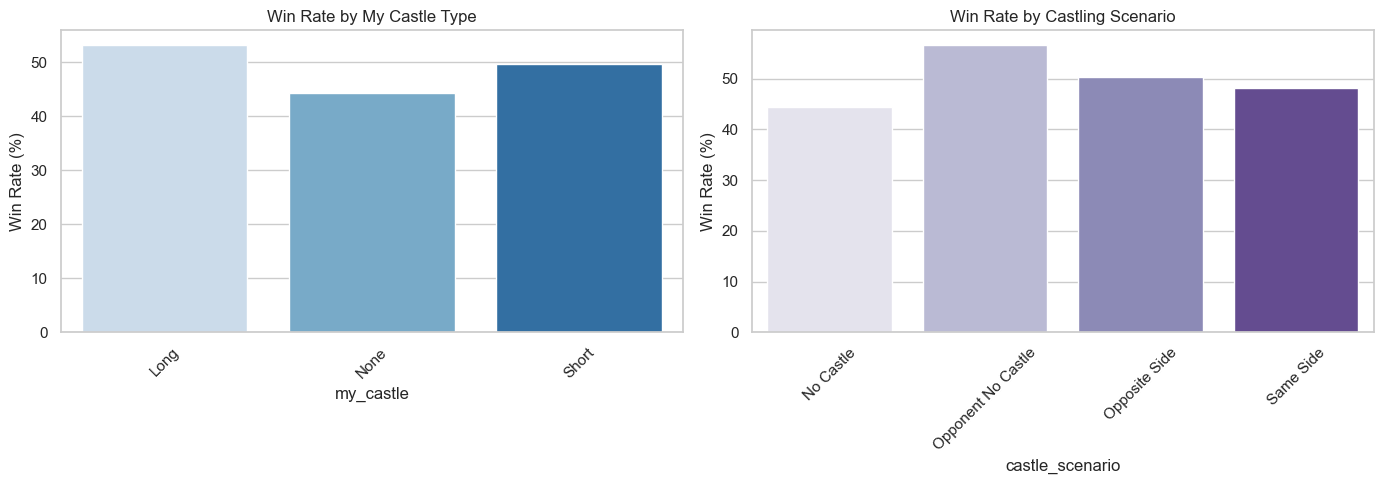

In [17]:
if not df_games.empty:
    data_analysis.analyze_castling(df_games)

### Analýza chyb a hrubek (Blunders)

In [18]:
if not df_moves.empty:
    data_analysis.test_blunder_by_piece(df_moves)


[Statistical hypothesis test] Blunder Rate by Piece Type
Chi-Square statistic=2018.5126, p-value=0.0000e+00
>> REJECT H0: Blunder rate depends on piece type.


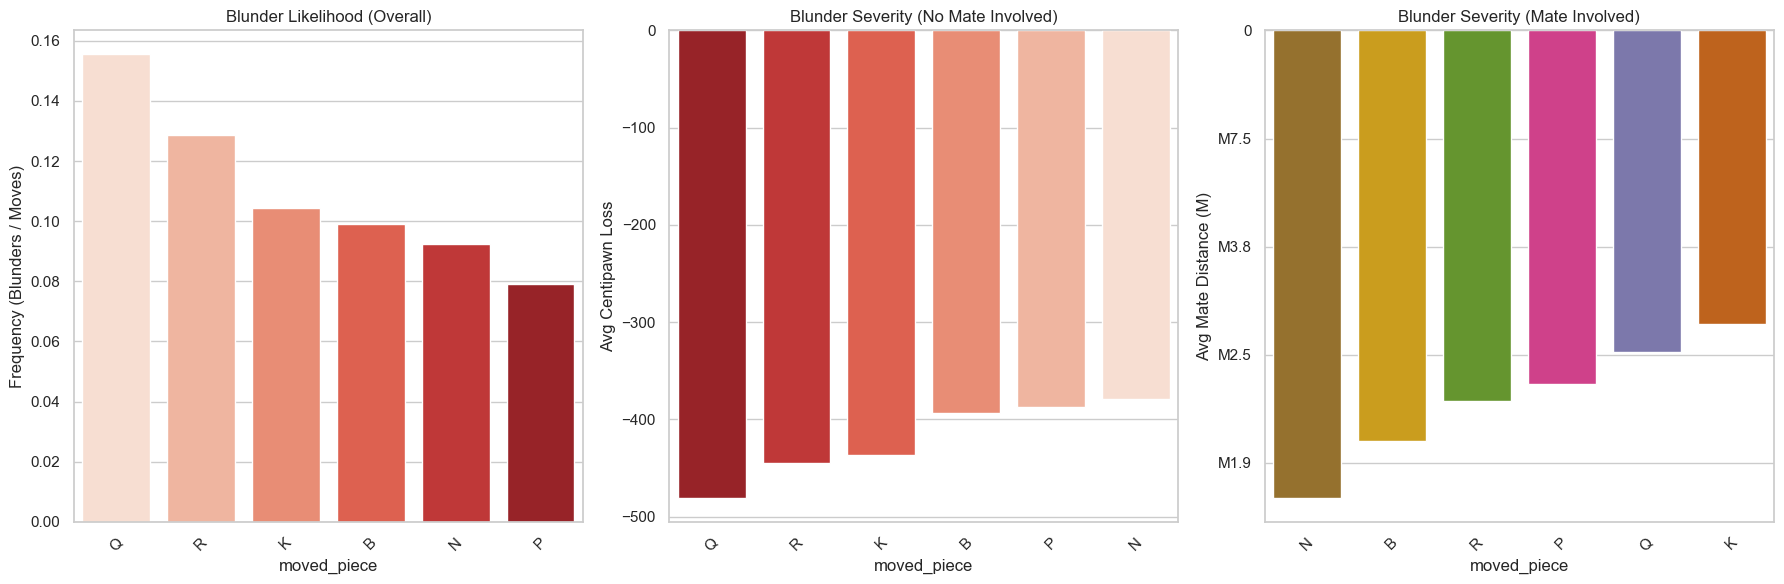

In [19]:
if not df_moves.empty:
    data_analysis.analyze_blunders(df_moves)

### Statistiky zahájení

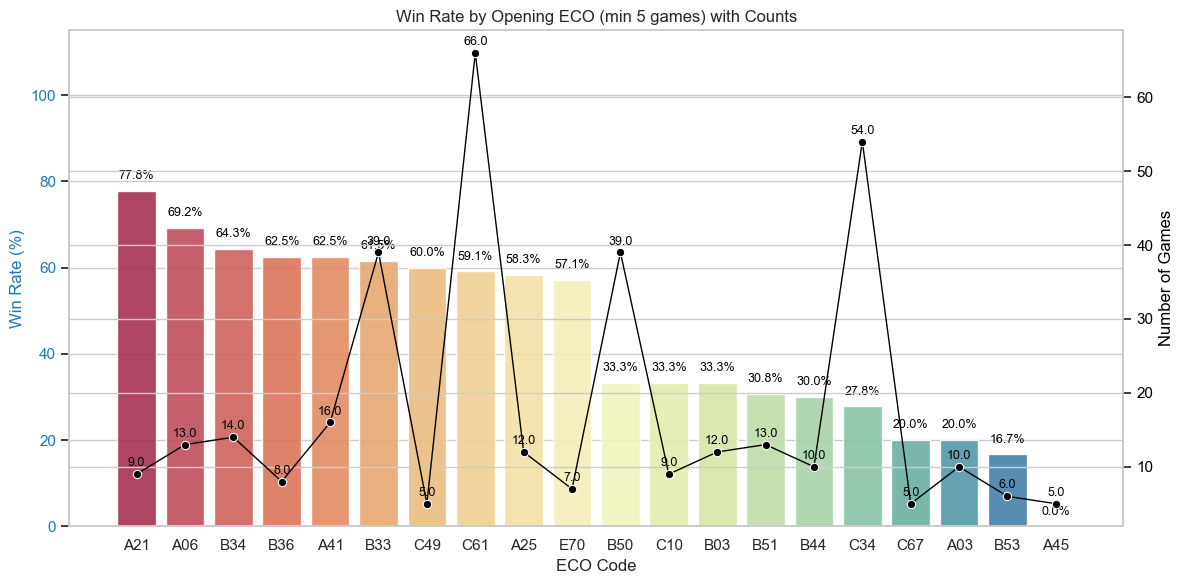

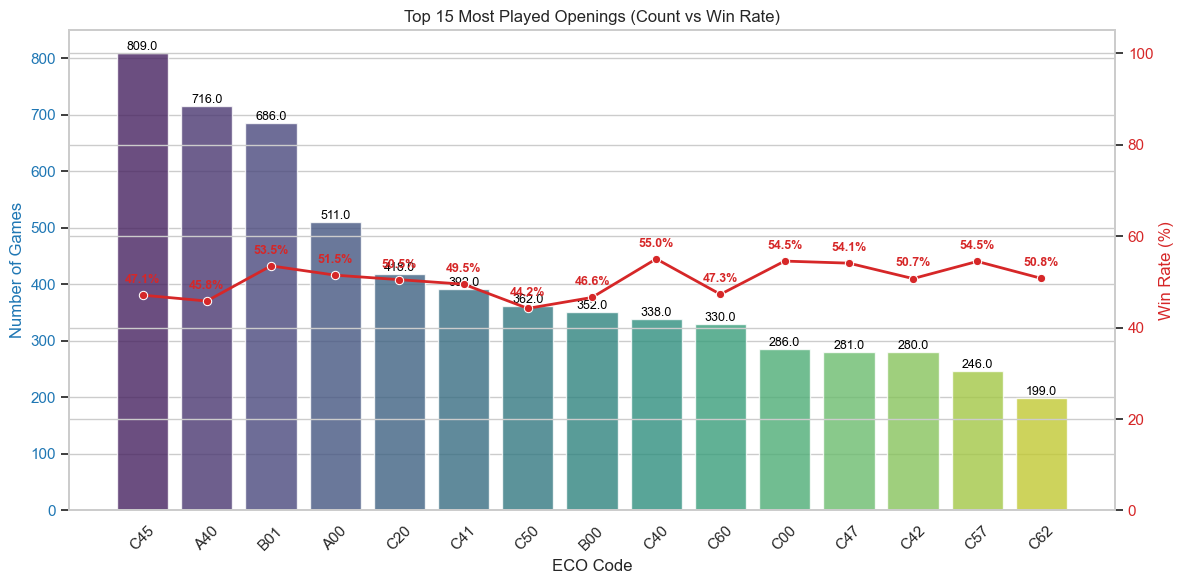

In [20]:
if not df_games.empty:
    data_analysis.plot_opening_winrate(df_games)
    data_analysis.plot_most_played_openings(df_games)

### Ragequit Analýza

Analyzing Ragequits (Eval Threshold: 3, Time Threshold: 20s)...
Total Games: 10106
Ragequits detected: 564 (5.58%)
  - Abandoned in lost position: 434
  - Stalled/Timeout in lost position (>10s left): 130


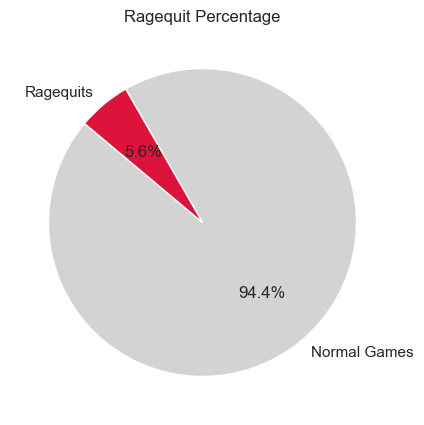

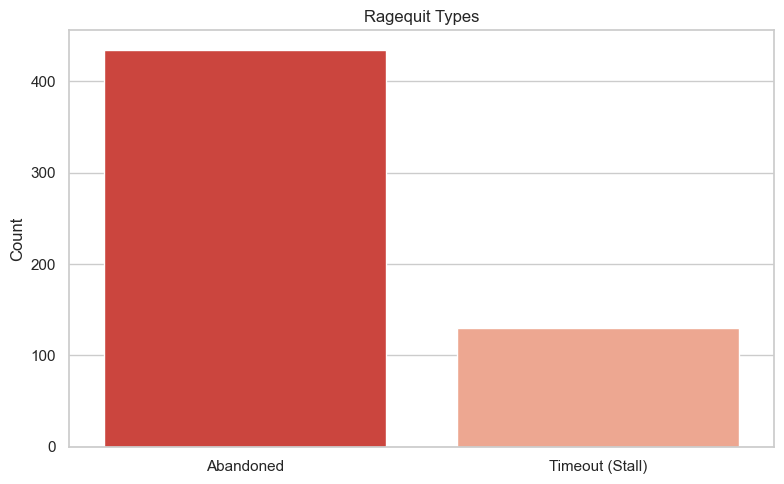

In [21]:
if not df_games.empty and not df_moves.empty:
    data_analysis.analyze_ragequits(df_games, df_moves, eval_threshold=3, time_threshold=20)

### Silné stránky


--- Strong Side Analysis (Player vs Opponent) ---


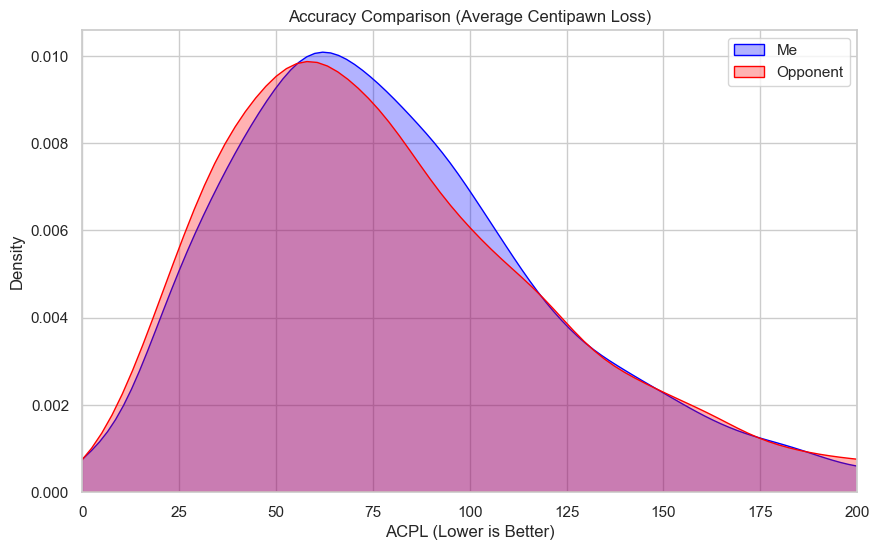

My Avg ACPL: 82.89
Opponent Avg ACPL: 83.48
Punishment Rate (I win when they blunder): 58.79%
Survival Rate (I win even if I blunder): 40.81%


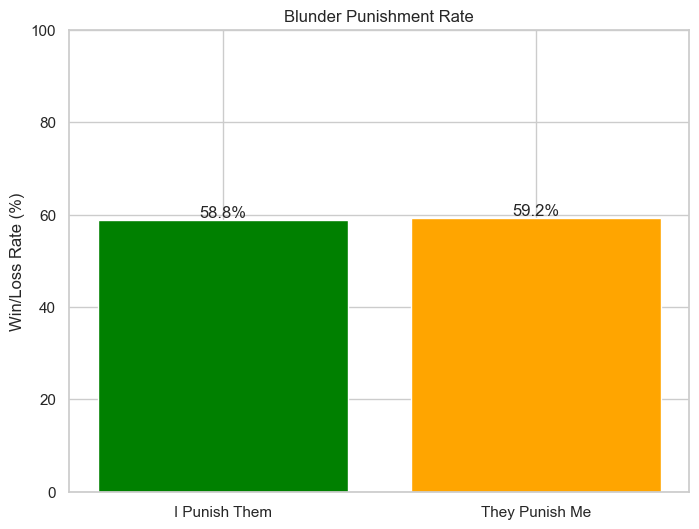

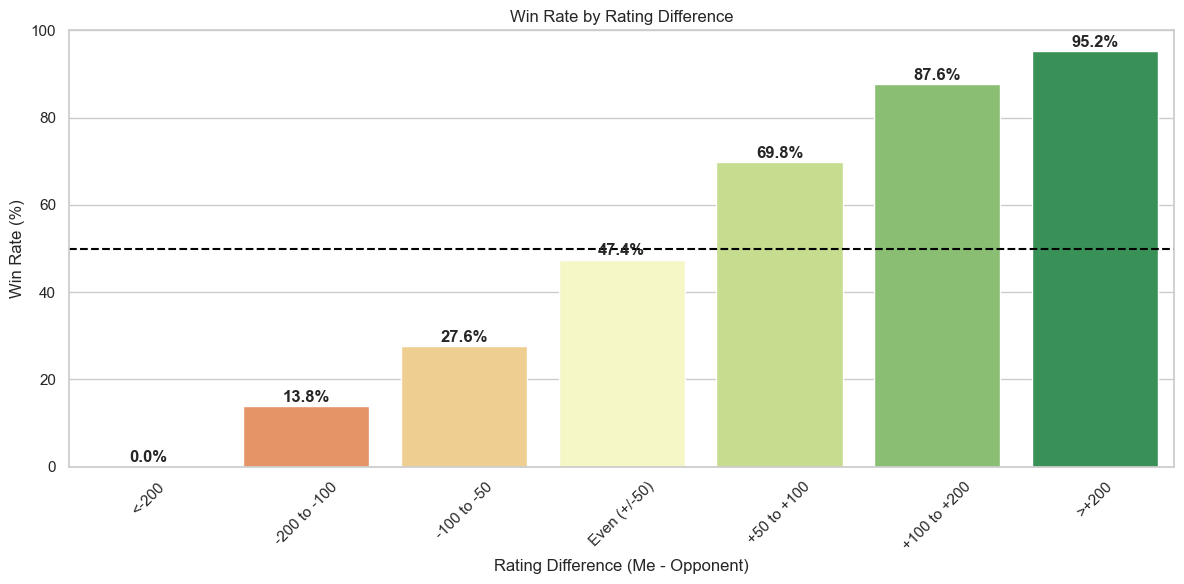

In [22]:
if not df_games.empty and not df_moves.empty:
    data_analysis.analyze_strong_side(df_games, df_moves)